In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, glob, zipfile

DRIVE_ROOTS = ['/content/drive/MyDrive', '/content/drive/My Drive']

RSN_DIR = None
for root in DRIVE_ROOTS:
    hits = glob.glob(f'{root}/**/je.py', recursive=True)
    if hits:
        RSN_DIR = os.path.dirname(hits[0]); break
if RSN_DIR is None:
    for root in DRIVE_ROOTS:
        zips = glob.glob(f'{root}/**/rsn_flat.zip', recursive=True)
        if zips:
            RSN_DIR = '/content/rsn_flat'
            with zipfile.ZipFile(zips[0]) as z:
                z.extractall(RSN_DIR)
            print('unzipped', zips[0], '->', RSN_DIR); break
if RSN_DIR is None:
    raise FileNotFoundError('rsn_flat.zip (or its extracted files) not found in Drive')

sys.path.insert(0, RSN_DIR)
print('using', RSN_DIR)

Mounted at /content/drive
using /content/drive/MyDrive/rsn_flat


In [ ]:
import numpy as np
from rsn import make_2lln, RSN
from offline import OfflineTables
from je import run_JE
from simulation import benchmark_hgi_e

net = make_2lln()                                  # paper Example 2.2
hhat = lambda W: np.asarray(W).max(axis=1)         # analytic ideal cost (2LLN)
print(net)

# faithful Definition 2.3 run — the SSC gap is the finite-r test
out = run_JE(net, r=50, T=10, c1=1.0, c2=4.0, kappa=0.15, seed=1, hhat_fn=hhat)
print(f"faithful:  J_E = {out['JE']:.3f} ± {out['JE_ci']:.3f}   "
      f"SSC gap = {out['ssc_gap']:.4f} ± {out['gap_ci']:.4f}")

# CONTROL EXPERIMENT (outside Definition 2.3): flags off (E_mask=0), ||v^b|| = 0.24 > b_max.
# A labeled departure for comparison only — NOT a recommended configuration.
res = run_JE(net, r=50, T=20, c1=1.0, c2=10.0, kappa=0.22, seed=1,
             E_mask=0, vb_norm=0.24, hhat_fn=hhat)
bench, se = benchmark_hgi_e(net, hhat_fn=hhat, T=20000.0, seeds=(0, 1))   # sqrt(dt)-extrapolated
print(f"control experiment (outside Def. 2.3): J_E = {res['JE']:.3f} ± {res['JE_ci']:.3f}")
print(f"benchmark:   HGI_E = {bench:.3f} ± {se:.3f}   "
      f"(level/benchmark = {res['JE']/bench:.2f})")

HGI_E = 1.3466 +- 0.0212   (the r -> infinity target)

    r      J_E  SSC gap   excess  % off HGI
   30    2.745    0.521    1.398     103.8%
   50    2.314    0.351    0.967      71.8%
  100    2.382    0.229    1.035      76.9%
  200    1.727    0.139    0.380      28.3%

theory: both columns shrink like r^(kappa-1) = r^(-0.78)
the SSC gap follows the law tightly; the level excess is noisier at
single seeds (average several seeds or extend T for smooth decay)


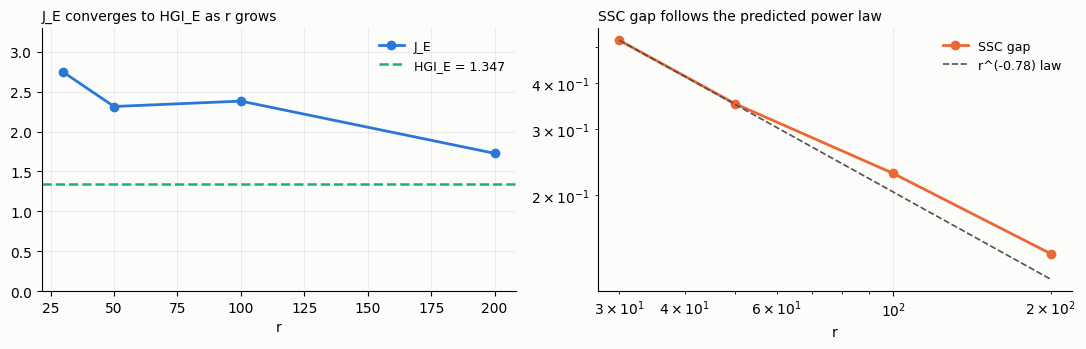

In [ ]:
# === Convergence of J_E toward HGI_E as r grows===
import time
import numpy as np, matplotlib.pyplot as plt
from rsn import make_2lln
from offline import OfflineTables
from policy import GeneralThresholdPolicy
from simulation import gillespie_ergodic, benchmark_hgi_e

net  = make_2lln(eta=(-1.0,)*3)               # theta = [-2,-2]
hhat = lambda W: np.asarray(W).max(axis=1)
tab  = OfflineTables(net, vb_norm=0.24)       # CONTROL EXPERIMENT (outside Def. 2.3): ||v^b|| > b_max
bench, se = benchmark_hgi_e(net, hhat_fn=hhat, T=20000.0, seeds=(0, 1))   # sqrt(dt)-extrapolated
print(f"HGI_E = {bench:.4f} +- {se:.4f}   (the r -> infinity target)\n")
print(f"{'r':>5} {'J_E':>8} {'SSC gap':>8} {'excess':>8} {'% off HGI':>10}")

RS = [(30, 40.0), (50, 40.0), (100, 30.0), (200, 20.0)]
rows = []
for r, T in RS:
    pol = GeneralThresholdPolicy(net, c1=1.0, c2=10.0, kappa=0.22,
                                 tables=tab, E_mask=0)   # control experiment: flags off
    out = gillespie_ergodic(net, pol, float(r), T_diff=T, burn_frac=0.3,
                            n_snapshots=600, rng=np.random.default_rng(1))
    rows.append((r, out["JE"], out["ssc_gap"]))
    print(f"{r:>5} {out['JE']:>8.3f} {out['ssc_gap']:>8.3f} "
          f"{out['JE']-bench:>8.3f} {100*(out['JE']-bench)/bench:>9.1f}%")

print("\ntheory: both columns shrink like r^(kappa-1) = r^(-0.78)")
print("the SSC gap follows the law tightly; the level excess is noisier at")
print("single seeds (average several seeds or extend T for smooth decay)")

rs   = [x[0] for x in rows]
jes  = [x[1] for x in rows]
gaps = [x[2] for x in rows]
BLUE, AQUA, ORANGE, SURF = "#2a78d6", "#1baf7a", "#eb6834", "#fcfcfb"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), facecolor=SURF)
for ax in axes:
    ax.set_facecolor(SURF); ax.grid(True, alpha=0.25, lw=0.6)
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
axes[0].plot(rs, jes, "-o", color=BLUE, lw=2, label="J_E")
axes[0].axhline(bench, color=AQUA, ls="--", lw=1.8, label=f"HGI_E = {bench:.3f}")
axes[0].set_xlabel("r"); axes[0].set_ylim(0, max(jes)*1.2)
axes[0].set_title("J_E converges to HGI_E as r grows", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=9)
axes[1].loglog(rs, gaps, "-o", color=ORANGE, lw=2, label="SSC gap")
ref = gaps[0] * (np.array(rs)/rs[0])**(-0.78)
axes[1].loglog(rs, ref, "--", color="#52514e", lw=1.2, label="r^(-0.78) law")
axes[1].set_xlabel("r")
axes[1].set_title("SSC gap follows the predicted power law", loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

FLAT_DIR = '/content/drive/MyDrive/rsn_flat'   # <-- edit if yours lives elsewhere

import os, sys, glob, json, time
if not os.path.exists(os.path.join(FLAT_DIR, 'rsn.py')):
    hits = glob.glob('/content/drive/MyDrive/**/rsn.py', recursive=True)
    assert hits, 'could not find rsn.py under MyDrive — set FLAT_DIR by hand'
    FLAT_DIR = os.path.dirname(hits[0])
    print('found rsn_flat at:', FLAT_DIR)
sys.path.insert(0, FLAT_DIR)

import numpy as np
from rsn import make_2lln
from je import run_JE
from simulation import benchmark_hgi_e

NET  = make_2lln()                                  # toy: theta=(-1,-1)
HHAT = lambda W: np.maximum(W[:, 0], W[:, 1])       # analytic hhat for the toy
KM_T = (NET.K @ NET.M).T
RESULTS = os.path.join(FLAT_DIR, 'convergence_results.json')

store = json.load(open(RESULTS)) if os.path.exists(RESULTS) else {}
def save():
    json.dump(store, open(RESULTS, 'w'), indent=1)

print(NET)
print('checkpoint file ->', RESULTS, f'({len(store)} entries loaded)')

Mounted at /content/drive
2LLN(I=2, J=3)
  alpha=[1. 1. 1.]
  beta =[1. 1. 1.]
  h    =[1. 1. 1.]
  rho  =[1. 1. 1.]  C=[2. 2.]
  eta  =[-0.5 -0.5 -0.5]
  theta=[-1. -1.]  [stable]
  local types s_i = {0: 0, 1: 1}
checkpoint file -> /content/drive/MyDrive/rsn_flat/convergence_results.json (27 entries loaded)


In [ ]:
# exact reflection map, sqrt(dt)-extrapolated from dt = (4e-3, 1e-3): 2.81 +/- 0.02.
# (A value from a fixed dt = 1e-3 run, 2.7446, is about 2% low; it is recomputed once.)
if not store.get('benchmark', {}).get('extrapolated'):
    t0 = time.time()
    m, se = benchmark_hgi_e(NET, hhat_fn=HHAT, dt=(4e-3, 1e-3), T=20000.0,
                            seeds=(0, 1, 2, 3))
    store['benchmark'] = dict(mean=float(m), se=float(se), extrapolated=True); save()
    print(f'HGI_E = {m:.4f} +/- {se:.4f}   ({time.time()-t0:.0f}s)')
else:
    b = store['benchmark']
    print(f"HGI_E = {b['mean']:.4f} +/- {b['se']:.4f}   (cached)")

HGI_E = 2.7446 +/- 0.0195   (11s)


In [ ]:
# smoke test of the engine. NOTE: E_mask=0 / vb_norm are the CONTROL EXPERIMENT (outside
# Definition 2.3); the sweep below is Definition 2.3 verbatim.
t0 = time.time()
out = run_JE(NET, r=50.0, T=4.0, c1=0.5, c2=10.0, kappa=0.22, seed=0,
             E_mask=0, vb_norm=0.95*NET.rho_star/4, n_snapshots=200,
             hhat_fn=HHAT)
print(f"ok: JE={out['JE']:.3f} gap={out['ssc_gap']:.3f} "
      f"({time.time()-t0:.0f}s) — safe to start the sweep")

ok: JE=5.793 gap=0.337 (5s) — safe to start the sweep


In [ ]:
# --- Cell 4: faithful-only sweep. Both variants are Definition 2.3 verbatim
# (hysteresis on, ||v^b|| within b_max); they differ ONLY in the definition's
# free constants: any 0 < c1 < c2 and kappa in (0, 1/4) are allowed.
CFG = {'faithful':       dict(c1=0.5, c2=10.0, kappa=0.22),  # comparability set
       'faithful_tuned': dict(c1=0.1, c2=30.0, kappa=0.24)}  # E14 best-in-definition

PLAN = []
for r, T, seeds in [(50, 20, 2), (100, 20, 2), (200, 20, 2), (400, 20, 2)]:
    for s in range(seeds):
        PLAN.append(dict(variant='faithful', r=r, T=T, seed=s))
for r, T, seeds in [(50, 40, 3), (100, 40, 3), (200, 40, 3),
                    (400, 40, 2), (700, 20, 2), (1000, 16, 1)]:
    for s in range(seeds):
        PLAN.append(dict(variant='faithful_tuned', r=r, T=T, seed=s))

def key(p):  return f"{p['variant']}|r={p['r']}|seed={p['seed']}"

# calibrate events/sec from whatever is already in the checkpoint file
done  = [v for v in store.values() if isinstance(v, dict) and v.get('minutes')]
rates = [5.5*v['r']**2*v['T']/(v['minutes']*60) for v in done]
RATE  = float(np.median(rates)) if rates else 9000.0
def est_min(p): return 5.5 * p['r']**2 * p['T'] / RATE / 60

todo = sorted([p for p in PLAN if key(p) not in store],
              key=lambda p: (p['r'], p['variant'], p['seed']))
print(f"{len(PLAN)-len(todo)} done, {len(todo)} to go "
      f"(ETA {sum(map(est_min, todo))/60:.1f} h at your measured speed)", flush=True)

for i, p in enumerate(todo):
    t0 = time.time()
    c  = CFG[p['variant']]
    out = run_JE(NET, r=float(p['r']), T=float(p['T']), c1=c['c1'],
                 c2=c['c2'], kappa=c['kappa'], seed=p['seed'],
                 n_snapshots=1200, hhat_fn=HHAT)
    W = (out['snapshots'] @ KM_T) / float(p['r'])
    level = float(HHAT(W).mean())
    store[key(p)] = dict(variant=p['variant'], r=p['r'], T=p['T'],
                         seed=p['seed'], JE=float(out['JE']),
                         JE_ci=float(out['JE_ci']), gap=float(out['ssc_gap']),
                         gap_ci=float(out['gap_ci']), level=level,
                         E_frac=float(out['E_frac']),
                         minutes=(time.time()-t0)/60)
    save()
    left = sum(est_min(q) for q in todo[i+1:])
    print(f"[{i+1}/{len(todo)}] {key(p)}: JE={out['JE']:.3f}"
          f"+/-{out['JE_ci']:.3f}  gap={out['ssc_gap']:.3f}  "
          f"level={level:.3f}  E_frac={out['E_frac']:.3f}  "
          f"({(time.time()-t0)/60:.1f} min; ~{left/60:.1f} h left)", flush=True)

print('sweep complete', flush=True)

4 done, 18 to go (ETA 9.9 h at your measured speed)
[1/18] faithful_tuned|r=50|seed=0: JE=4.913+/-0.576  gap=1.019  level=3.892  E_frac=0.022  (1.0 min; ~9.9 h left)
[2/18] faithful_tuned|r=50|seed=1: JE=6.435+/-1.177  gap=0.999  level=5.427  E_frac=0.023  (1.0 min; ~9.9 h left)
[3/18] faithful_tuned|r=50|seed=2: JE=6.127+/-0.797  gap=1.007  level=5.120  E_frac=0.027  (1.0 min; ~9.8 h left)
[4/18] faithful_tuned|r=100|seed=0: JE=7.277+/-2.389  gap=0.645  level=6.628  E_frac=0.015  (3.7 min; ~9.8 h left)
[5/18] faithful_tuned|r=100|seed=1: JE=13.869+/-2.495  gap=0.650  level=13.212  E_frac=0.012  (3.7 min; ~9.7 h left)
[6/18] faithful_tuned|r=100|seed=2: JE=3.396+/-0.360  gap=0.624  level=2.777  E_frac=0.017  (3.7 min; ~9.6 h left)
[7/18] faithful|r=200|seed=0: JE=51.456+/-8.992  gap=0.113  level=51.318  E_frac=0.048  (7.1 min; ~9.5 h left)
[8/18] faithful|r=200|seed=1: JE=64.023+/-9.537  gap=0.114  level=63.884  E_frac=0.051  (7.4 min; ~9.4 h left)
[9/18] faithful_tuned|r=200|seed=0: J

HGI_E benchmark = 2.745 +/- 0.020

variant             r  n     J_E    +/-   level     gap  E_frac  lvl/HGI
------------------------------------------------------------------------
faithful           50  2  18.263  1.581  17.933   0.326   0.078    6.534
faithful          100  2  27.810  7.045  27.608   0.193   0.062   10.059
faithful          200  2  57.740  8.886  57.601   0.114   0.049   20.987
faithful          400  2  95.988  1.311  95.881   0.065   0.042   34.934
faithful_tuned     50  3   5.825  0.804   4.813   1.008   0.024    1.754
faithful_tuned    100  3   8.181  5.295   7.539   0.640   0.015    2.747
faithful_tuned    200  3   6.349  3.897   5.962   0.392   0.008    2.172
faithful_tuned    400  2   5.167  2.917   4.932   0.238   0.005    1.797
faithful_tuned    700  2   4.742  1.051   4.582   0.160   0.003    1.669
faithful_tuned   1000  1   4.773  0.000   4.645   0.124   0.002    1.692
noE_vbcap          50  3   3.436  0.498   3.068   0.372   0.000    1.118
noE_vbcap       

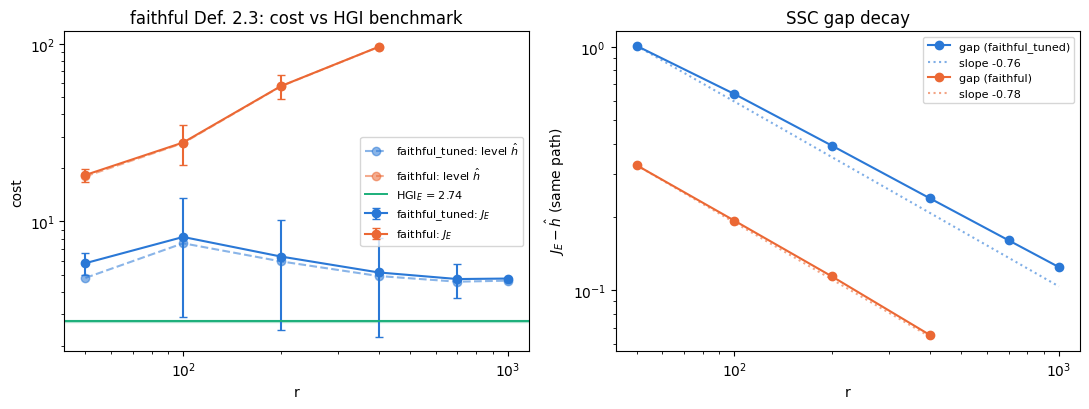

In [ ]:
import matplotlib.pyplot as plt
store = json.load(open(RESULTS))
bench, bse = store['benchmark']['mean'], store['benchmark']['se']
runs = [v for k, v in store.items() if k != 'benchmark']

agg = {}
for v in runs:
    agg.setdefault((v['variant'], v['r']), []).append(v)
rows = []
for (var, r), grp in sorted(agg.items()):
    je = np.mean([g['JE'] for g in grp])
    sd = np.std([g['JE'] for g in grp], ddof=1) if len(grp) > 1 else 0.0
    rows.append(dict(variant=var, r=r, n=len(grp), JE=je, sd=sd,
                     level=np.mean([g['level'] for g in grp]),
                     gap=np.mean([g['gap'] for g in grp]),
                     E_frac=np.mean([g['E_frac'] for g in grp])))

print(f'HGI_E benchmark = {bench:.3f} +/- {bse:.3f}\n')
hdr = f"{'variant':<15}{'r':>6}{'n':>3}{'J_E':>8}{'+/-':>7}{'level':>8}" \
      f"{'gap':>8}{'E_frac':>8}{'lvl/HGI':>9}"
print(hdr); print('-' * len(hdr))
for w in rows:
    print(f"{w['variant']:<15}{w['r']:>6}{w['n']:>3}{w['JE']:>8.3f}"
          f"{w['sd']:>7.3f}{w['level']:>8.3f}{w['gap']:>8.3f}"
          f"{w['E_frac']:>8.3f}{w['level']/bench:>9.3f}")

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
KAP = {'faithful': 0.22, 'faithful_tuned': 0.24}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for var, col in [('faithful_tuned', BLUE), ('faithful', ORANGE)]:
    sel = sorted([w for w in rows if w['variant'] == var], key=lambda w: w['r'])
    if not sel: continue
    rs = [w['r'] for w in sel]
    ax1.errorbar(rs, [w['JE'] for w in sel], yerr=[w['sd'] for w in sel],
                 marker='o', color=col, label=f'{var}: $J_E$', capsize=3)
    ax1.plot(rs, [w['level'] for w in sel], 'o--', color=col, alpha=0.55,
             label=f'{var}: level $\\hat h$')
    gs = [(w['r'], w['gap']) for w in sel if w['gap'] > 0]
    if gs:
        gr, gp = np.array([g[0] for g in gs], float), np.array([g[1] for g in gs])
        ax2.loglog(gr, gp, 'o-', color=col, label=f'gap ({var})')
        ax2.loglog(gr, gp[0]*(gr/gr[0])**(KAP[var]-1), ':', color=col,
                   alpha=0.6, label=f'slope {KAP[var]-1:.2f}')
ax1.axhspan(bench-2*bse, bench+2*bse, color=AQUA, alpha=0.25)
ax1.axhline(bench, color=AQUA, lw=1.4, label=f'HGI$_E$ = {bench:.2f}')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xlabel('r'); ax1.set_ylabel('cost')
ax1.set_title('faithful Def. 2.3: cost vs HGI benchmark'); ax1.legend(fontsize=8)
ax2.set_xlabel('r'); ax2.set_ylabel('$J_E - \\hat h$ (same path)')
ax2.set_title('SSC gap decay'); ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FLAT_DIR, 'convergence_fig.png'), dpi=150)
plt.show()